# Multivariate Data and the Grammar of Graphics

In [1]:
import pandas as pd
df = pd.read_csv("https://datasci112.stanford.edu/data/penguins.csv")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


## Review

In [2]:
df[["species", "island"]].value_counts().unstack().fillna(0)

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44.0,56.0,52.0
Chinstrap,0.0,68.0,0.0
Gentoo,124.0,0.0,0.0


In [3]:
df.groupby("species")[["bill_length_mm", "bill_depth_mm"]].mean()

,bill_length_mm,bill_depth_mm
species,,
Adelie,38.791391,18.346358
Chinstrap,48.833824,18.420588
Gentoo,47.504878,14.982114


In [4]:
df[["bill_length_mm", "bill_depth_mm"]].mean()

,0
bill_length_mm,43.92193
bill_depth_mm,17.15117


## Relationships between Quantitative Variables

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

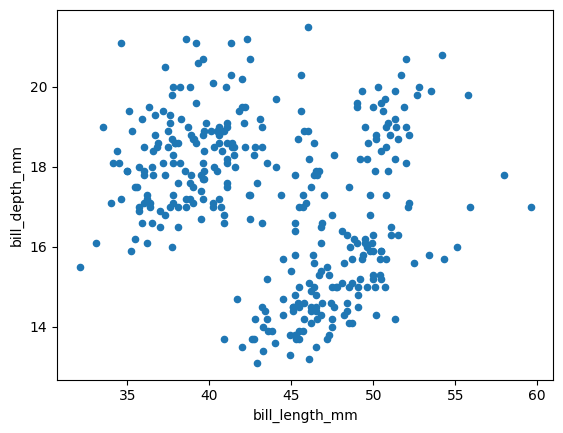

In [5]:
df.plot.scatter(x="bill_length_mm", y="bill_depth_mm")

In [6]:
# calculating r manually
x = df["bill_length_mm"]
y = df["bill_depth_mm"]
n = (~x.isnull() & ~y.isnull()).sum()

r = (((x - x.mean()) / x.std()) * ((y - y.mean()) / y.std())).sum() / (n - 1)
r

np.float64(-0.23505287035553266)

In [7]:
df[["bill_length_mm", "bill_depth_mm"]].corr()

,bill_length_mm,bill_depth_mm
bill_length_mm,1.000000,-0.235053
bill_depth_mm,-0.235053,1.000000


## Plotly

In [8]:
import plotly.express as px

Let's create a scatterplot where we map:

- x --> bill length
- y --> bill depth
- color --> species

As a bonus, all of the plots that Plotly makes are interactive! Try hovering your cursor over a point or selecting a region of the scatterplot.

In [9]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm", color="species")

What is the correlation between bill length and bill depth, conditional on species?

In [10]:
df.groupby("species")[["bill_length_mm", "bill_depth_mm"]].corr()

bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000

We can make facets using `facet_row=` or `facet_col=`. For example, if we wanted to represent species using columns (instead of color), then we would do the following:

In [11]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm",
           facet_col="species")

You can have both row and column facets.

In [12]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm",
           facet_col="species", facet_row="island")

Remember that in the grammar of graphics, you can have aesthetic mappings with any type of geometric object. So try Plotly on bar plots and histograms!

In [13]:
px.histogram(df, x="bill_length_mm", facet_col="species")

## Other Aesthetic Mappings

The Grammar of Graphics allows us to map variables to many different visual properties beyond just x, y, and color.

First let's drop missing values:

In [14]:
df = df.dropna()

### Symbol

We can map a categorical variable to the shape of the points using the `symbol` aesthetic.

In [15]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm",
           color="species", symbol="island")

### Size

We can map a quantitative variable to the size of the points. Here, we'll map `body_mass_g` to size.

In [16]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm",
           color="species", size="body_mass_g")

### Continuous Color

Aesthetic mappings aren't limited to categorical variables. We can map a quantitative variable to a color scale.

In [17]:
px.scatter(df, x="bill_length_mm", y="flipper_length_mm",
           color="body_mass_g")

### Combining Mappings

One of the strengths of the grammar of graphics is that we can combine many mappings to visualize multiple dimensions of data simultaneously.



In [18]:
px.scatter(df, x="bill_length_mm", y="bill_depth_mm",
           color="species",
           symbol="sex",
           size="body_mass_g",
           facet_col="island",
           title="Penguin Dimensions by Species, Sex, and Island")

**Just because we *can* do all these things, doesn't mean we should!**